
# Wearable Feature Engineering

## Overview

This notebook demonstrates a reusable Python pipeline for deriving
participant-level features from longitudinal wearable data.

The example uses **entirely synthetic data** representing 20 fictional
participants monitored for 30 days.

Features include:

- Summary statistics for sleep, HRV, and physical activity
- Linear temporal trends
- Within-person variability
- Circular sleep-timing statistics

The demonstration is intended for computational education and
reproducibility, not clinical decision-making.



## 1. Load synthetic wearable data

The input dataset contains daily observations of sleep duration,
sleep efficiency, HRV, steps, activity minutes, bedtime, and wake time.


In [1]:

from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

# Locate repository root from the notebook directory
PROJECT_ROOT = Path.cwd().resolve().parent

if not (PROJECT_ROOT / "src" / "wearable_features").exists():
    raise FileNotFoundError(
        "Run this notebook from the repository's notebooks folder."
    )

sys.path.insert(0, str(PROJECT_ROOT))

from src.wearable_features.pipeline import build_feature_dataset

data = pd.read_csv(
    PROJECT_ROOT / "data" / "synthetic_wearable_data.csv",
    parse_dates=["date"]
)

print("Input shape:", data.shape)
display(data.head())


Input shape: (600, 9)


,participant_id,date,sleep_duration_min,sleep_efficiency_pct,bedtime_hour,wake_hour,hrv_rmssd_ms,steps,activity_minutes
0,P001,2026-01-01,405.1,86.8,22.162,4.913,39.7,9817.0,43.0
1,P001,2026-01-02,477.9,86.4,21.856,5.820,52.7,10785.0,NaN
2,P001,2026-01-03,417.1,91.3,22.368,5.320,42.1,9481.0,46.0
3,P001,2026-01-04,445.3,83.4,NaN,5.303,39.4,10915.0,61.0
4,P001,2026-01-05,465.7,98.8,22.004,5.766,38.9,8826.0,NaN



## 2. Generate participant-level features

The pipeline combines four modules:

1. Summary features
2. Temporal trends
3. Within-person variability
4. Circular sleep-timing features

Each participant receives one row of derived features.


In [2]:

features = build_feature_dataset(data)

print("Feature dataset shape:", features.shape)

display(features.head())


Feature dataset shape: (20, 46)


,participant_id,sleep_duration_min_mean,sleep_duration_min_median,sleep_duration_min_std,sleep_duration_min_count,sleep_efficiency_pct_mean,sleep_efficiency_pct_median,sleep_efficiency_pct_std,sleep_efficiency_pct_count,hrv_rmssd_ms_mean,...,steps_adjacent_pairs,activity_minutes_cv_pct,activity_minutes_successive_rmssd,activity_minutes_adjacent_pairs,bedtime_hour_circular_mean,bedtime_hour_circular_sd,bedtime_hour_count,wake_hour_circular_mean,wake_hour_circular_sd,wake_hour_count
0,P001,450.800000,459.25,31.731398,26,86.925000,86.40,6.229299,28,41.662963,...,29,20.702126,12.984941,23,21.625497,0.566575,28,5.077655,0.574724,26
1,P002,494.250000,495.25,35.594782,28,86.111538,87.65,6.097300,26,57.282143,...,21,57.960336,23.028678,25,0.039593,0.521034,27,8.424780,0.959435,25
2,P003,447.464286,453.00,37.453727,28,84.496296,84.80,5.335403,27,71.287500,...,26,30.867319,23.859589,25,23.517595,0.525401,29,7.049521,0.858589,29
3,P004,425.153571,418.90,33.278583,28,85.158621,86.90,6.603598,29,46.334483,...,23,55.415299,21.025864,23,22.436047,0.590762,28,5.477753,0.800885,26
4,P005,468.810345,476.10,37.493679,29,85.326667,85.15,6.229127,30,69.670000,...,29,51.475443,18.372410,22,23.161798,0.671317,27,6.995302,0.884294,27



## 3. Examine selected features

We can inspect a subset of the derived features to understand
differences between fictional participants.


In [3]:

selected = [
    "participant_id",
    "sleep_duration_min_mean",
    "sleep_duration_min_slope",
    "sleep_duration_min_successive_rmssd",
    "hrv_rmssd_ms_mean",
    "steps_mean",
    "bedtime_hour_circular_mean"
]

display(features[selected].head(10).round(2))


,participant_id,sleep_duration_min_mean,sleep_duration_min_slope,sleep_duration_min_successive_rmssd,hrv_rmssd_ms_mean,steps_mean,bedtime_hour_circular_mean
0,P001,450.80,0.29,50.92,41.66,9686.50,21.63
1,P002,494.25,-1.33,52.92,57.28,6181.38,0.04
2,P003,447.46,-0.12,52.31,71.29,9448.14,23.52
3,P004,425.15,-0.52,44.00,46.33,5858.74,22.44
4,P005,468.81,-1.90,41.43,69.67,6813.97,23.16
5,P006,501.90,-0.20,54.67,52.43,10199.55,23.03
6,P007,489.33,-0.02,40.29,49.67,6350.54,23.15
7,P008,463.27,0.25,51.28,39.13,7789.38,22.24
8,P009,449.94,1.29,52.63,60.68,8203.10,23.64
9,P010,406.37,-0.43,54.42,57.12,7853.07,22.48



## 4. Visualize longitudinal observations

Participant-level features summarize the underlying daily measurements.
The figure below shows the nightly sleep-duration observations for one
fictional participant, including missing measurements.


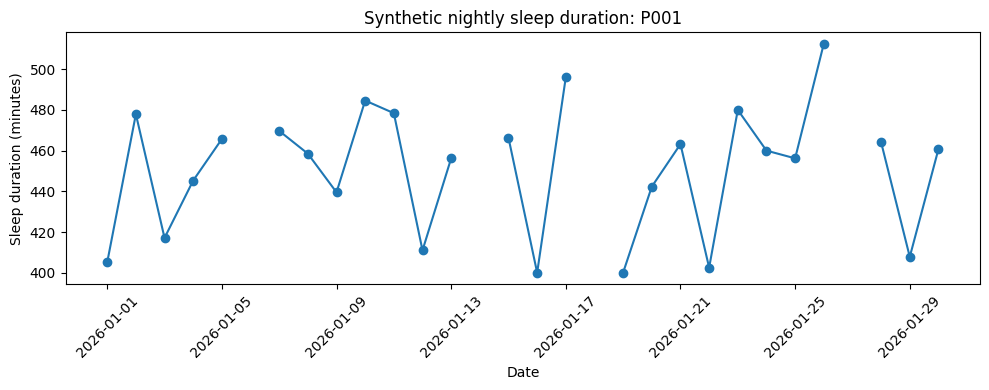

In [4]:

participant = data.loc[
    data["participant_id"] == "P001"
].sort_values("date")

plt.figure(figsize=(10, 4))

plt.plot(
    participant["date"],
    participant["sleep_duration_min"],
    marker="o"
)

plt.title("Synthetic nightly sleep duration: P001")
plt.xlabel("Date")
plt.ylabel("Sleep duration (minutes)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



## 5. Interpretation and limitations

The derived features describe different characteristics of
longitudinal wearable measurements.

- **Means** summarize typical measurement levels.
- **Slopes** describe linear changes over calendar time.
- **Variability measures** describe dispersion and successive changes.
- **Circular statistics** account for the 24-hour structure of clock time.

Missing observations are excluded from calculations as appropriate.
Successive-difference RMSSD uses only adjacent calendar-day pairs.

The pipeline does not currently enforce a universal minimum
completeness threshold. Researchers should evaluate data completeness,
measurement validity, and the suitability of each feature for their
specific application.

All observations are synthetic.
